<br>

# `# FPN -> Feature Pyramid Networks(FPN)

<br>
<br>

In standard CNNs, deep layers reduce spatial resolution through striding and pooling. While this helps the network recognize large objects and high-level context, **tiny objects get lost or blurred out completely**.

Feature Pyramid Networks (FPN) solve this exact problem by combining two strengths:

* **High Spatial Resolution (Shallow Layers, e.g., `fpn2`):** Retains fine details, sharp edges, and exact pixel boundaries for small objects.
* **High Semantic Context (Deep Layers, e.g., `fpn5`):** Captures broad context needed to reliably identify complex and large objects.

By fusing deep semantic context back into the high-resolution shallow feature maps, FPN gives small objects both **fine detail** and **strong contextual understanding**.

Whenever your dataset features a wide variance in object sizes—and missing small details is unacceptable (such as in satellite imagery, medical scans, or autonomous driving)—pyramid architectures are the standard solution.


<br>
<br>

In [1]:


import torch
import torch.nn as nn 
import torch.nn.functional as F


from skimage import data
import matplotlib.pyplot as plt 


In [2]:

demo_img1d = torch.tensor(
    data=[
        [1,2,2,2,1],
        [1,2,2,2,1],
        [1,2,2,2,1],
        [1,2,2,2,1],
        [1,2,2,2,1],
    ],
    dtype=torch.float32
)
demo_img1d = demo_img1d.unsqueeze(0).unsqueeze(0)

print(demo_img1d.shape)
print(demo_img1d)
print()
print(F.interpolate(demo_img1d,size=(10,10),mode="nearest"))


torch.Size([1, 1, 5, 5])
tensor([[[[1., 2., 2., 2., 1.],
          [1., 2., 2., 2., 1.],
          [1., 2., 2., 2., 1.],
          [1., 2., 2., 2., 1.],
          [1., 2., 2., 2., 1.]]]])

tensor([[[[1., 1., 2., 2., 2., 2., 2., 2., 1., 1.],
          [1., 1., 2., 2., 2., 2., 2., 2., 1., 1.],
          [1., 1., 2., 2., 2., 2., 2., 2., 1., 1.],
          [1., 1., 2., 2., 2., 2., 2., 2., 1., 1.],
          [1., 1., 2., 2., 2., 2., 2., 2., 1., 1.],
          [1., 1., 2., 2., 2., 2., 2., 2., 1., 1.],
          [1., 1., 2., 2., 2., 2., 2., 2., 1., 1.],
          [1., 1., 2., 2., 2., 2., 2., 2., 1., 1.],
          [1., 1., 2., 2., 2., 2., 2., 2., 1., 1.],
          [1., 1., 2., 2., 2., 2., 2., 2., 1., 1.]]]])


torch.Size([1, 3, 512, 512])
torch.Size([1, 128, 255, 255])
====================After Conv-1====================


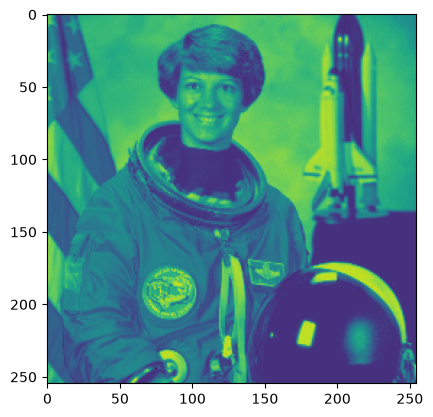

====================After Conv-2====================


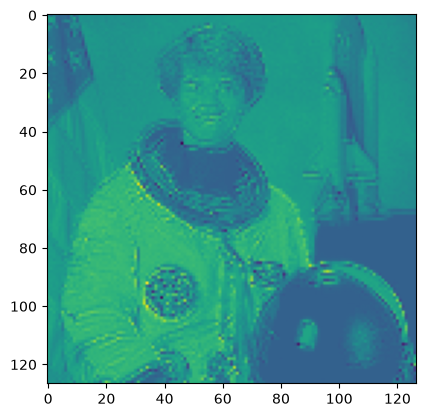

====================After Conv-3====================


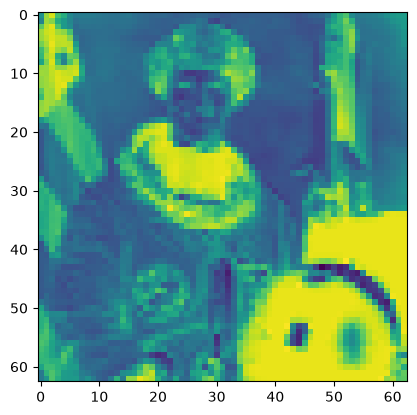

====================After Conv-4====================


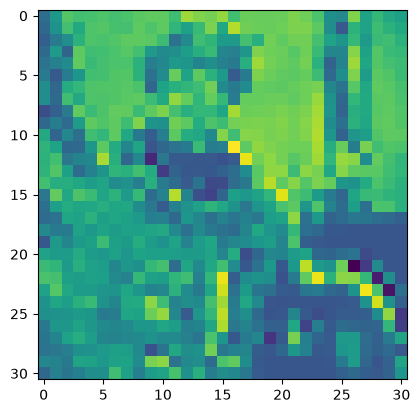

====================After Conv-5====================


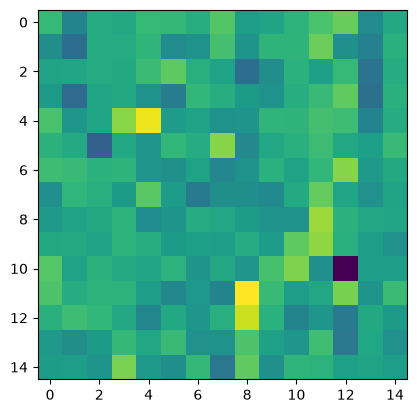

In [3]:


class NormalConvNN(nn.Module):
    def __init__(self,inp_dim=3):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=inp_dim,out_channels=128,kernel_size=(3,3),stride=2)
        self.conv2 = nn.Conv2d(in_channels=128,out_channels=256,kernel_size=(3,3),stride=2)
        self.conv3 = nn.Conv2d(in_channels=256,out_channels=512,kernel_size=(3,3),stride=2)
        self.conv4 = nn.Conv2d(in_channels=512,out_channels=1024,kernel_size=(3,3),stride=2)
        self.conv5 = nn.Conv2d(in_channels=1024,out_channels=2048,kernel_size=(3,3),stride=2)
        
    def forward(self,x):
        x = self.conv1(x)
        print(x.shape)
        print("====================After Conv-1====================")
        # batch[0], channel 0 -> [512,512]
        plt.imshow(x[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        x = self.conv2(x)
        print("====================After Conv-2====================")
        plt.imshow(x[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        x = self.conv3(x)
        print("====================After Conv-3====================")
        plt.imshow(x[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        x = self.conv4(x)
        print("====================After Conv-4====================")
        plt.imshow(x[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        x = self.conv5(x)
        print("====================After Conv-5====================")
        plt.imshow(x[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        

normalNN = NormalConvNN()
img = data.astronaut()
img = torch.tensor(img,dtype=torch.float32).permute(2,0,1).unsqueeze(0)
print(img.shape)
normalNN(img)

        



I) Let's implement this FPN:




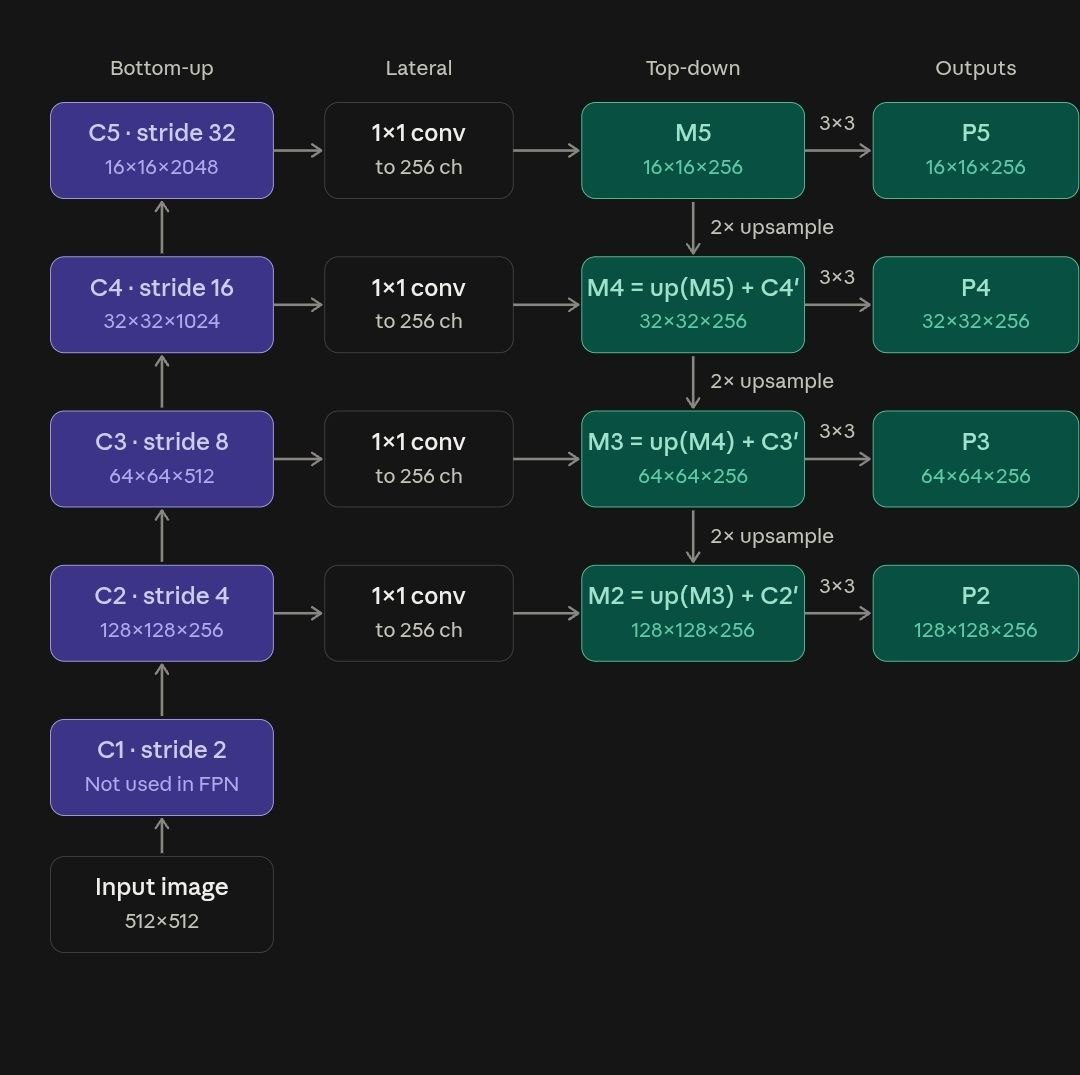

In [4]:

from IPython.display import Image

print("""
      
I) Let's implement this FPN:
      
""")
Image("../note/img/image-283.png")


torch.Size([1, 3, 512, 512])
torch.Size([1, 128, 255, 255])
====================After Conv-1====================


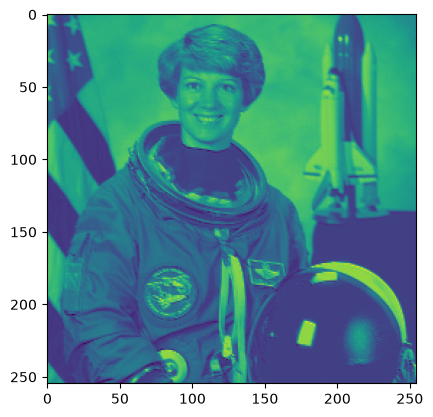

====================After Conv-2====================


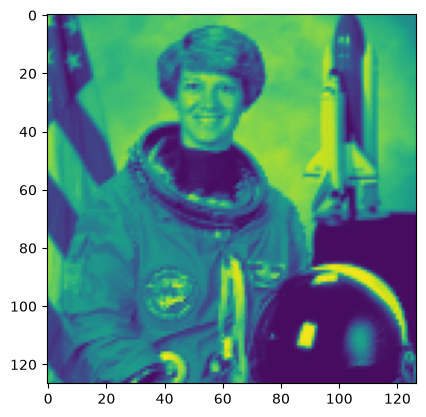

====================After Conv-3====================


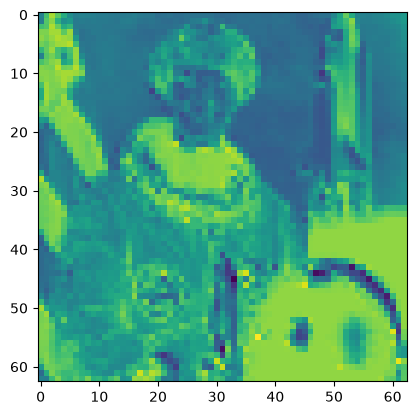

====================After Conv-4====================


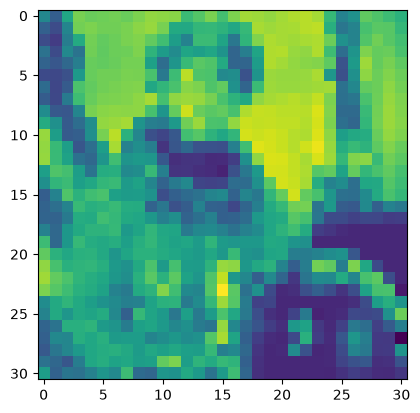

====================After Conv-5====================


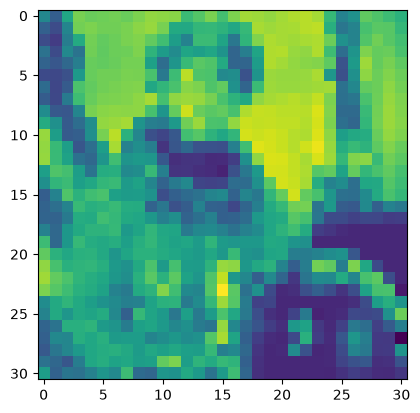

==================== FPN_OUR: fpn5 ====================


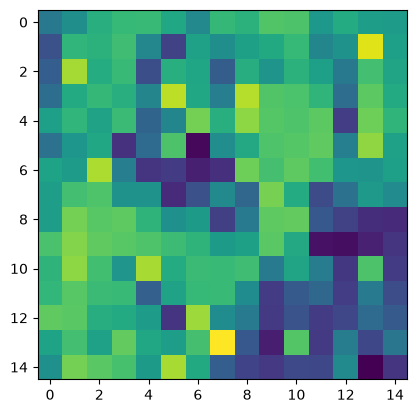

==================== FPN_OUR: fpn4 ====================


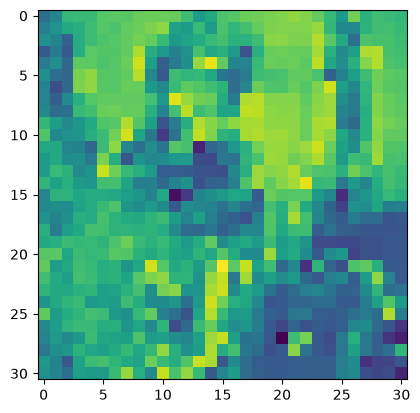

==================== FPN_OUR: fpn3 ====================


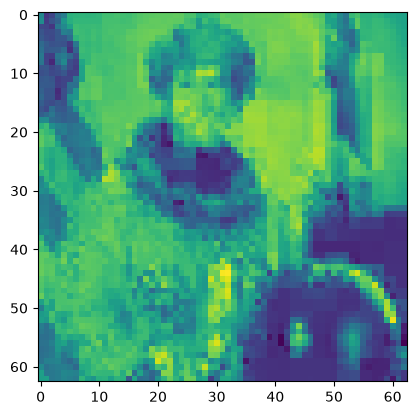

==================== FPN_OUR: fpn2 ====================


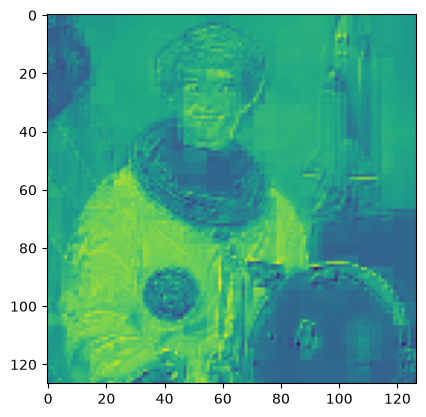

In [5]:


class FPNConvNN(nn.Module):
    def __init__(self,inp_dim=3):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=inp_dim,out_channels=128,kernel_size=(3,3),stride=2)
    
        self.conv2 = nn.Conv2d(in_channels=128,out_channels=256,kernel_size=(3,3),stride=2)
        self.fpn2 = nn.Conv2d(in_channels=256,out_channels=256,kernel_size=(1,1))
        
        self.conv3 = nn.Conv2d(in_channels=256,out_channels=512,kernel_size=(3,3),stride=2)
        self.fpn3 = nn.Conv2d(in_channels=512,out_channels=256,kernel_size=(1,1))
        
        self.conv4 = nn.Conv2d(in_channels=512,out_channels=1024,kernel_size=(3,3),stride=2)
        self.fpn4 = nn.Conv2d(in_channels=1024,out_channels=256,kernel_size=(1,1))
        
        self.conv5 = nn.Conv2d(in_channels=1024,out_channels=2048,kernel_size=(3,3),stride=2)
        self.fpn5 = nn.Conv2d(in_channels=2048,out_channels=256,kernel_size=(1,1))
        
    def forward(self,x):
        
        # bottom-up pass:
        out1 = self.conv1(x)
        print(out1.shape)
        print("====================After Conv-1====================")
        # batch[0], channel 0 -> [512,512]
        plt.imshow(out1[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        
        out2 = self.conv2(out1)
        print("====================After Conv-2====================")
        plt.imshow(out2[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        
        out3 = self.conv3(out2)
        print("====================After Conv-3====================")
        plt.imshow(out3[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        
        out4 = self.conv4(out3)
        print("====================After Conv-4====================")
        plt.imshow(out4[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        
        out5 = self.conv5(out4)
        print("====================After Conv-5====================")
        plt.imshow(out4[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        
        
        # fpn network: 
        fpn5 = self.fpn5(out5)
        fpn4 = self.fpn4(out4)
        fpn3 = self.fpn3(out3)
        fpn2 = self.fpn2(out2)
        
        # upsampling and merging:(There is no learning parameter)
        # so, we can't use nn.ConvTranspose2d:
        out_fpn5 = fpn5
        print("==================== FPN_OUR: fpn5 ====================")
        plt.imshow(out_fpn5[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
                
        out_fpn4 = fpn4 + F.interpolate(input=out_fpn5,size=fpn4.shape[-2:],mode="nearest")
        print("==================== FPN_OUR: fpn4 ====================")
        plt.imshow(out_fpn4[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
   
        out_fpn3 = fpn3 + F.interpolate(input=out_fpn4,size=fpn3.shape[-2:],mode="nearest")
        print("==================== FPN_OUR: fpn3 ====================")
        plt.imshow(out_fpn3[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        
        out_fpn2 = fpn2 + F.interpolate(input=out_fpn3,size=fpn2.shape[-2:],mode="nearest")
        print("==================== FPN_OUR: fpn2 ====================")
        plt.imshow(out_fpn2[0, 0].detach().cpu().numpy(), cmap='viridis')
        plt.show()
        
        return out_fpn2,out_fpn3, out_fpn4, out_fpn5
    
        
    
fpnNN = FPNConvNN()
img = data.astronaut()
img = torch.tensor(img,dtype=torch.float32).permute(2,0,1).unsqueeze(0)
print(img.shape)
fp = fpnNN(img)

        

<br>
<br>
<br>

# `#02: Pre-trained models FPN apply`

<br>
<br>
<br>

